# Email Campaign Experiment Analysis

### Measuring Campaign Lift, Customer Funnel Performance, and Revenue Impact

This project evaluates two targeted email campaigns against a no-email control group to determine:

1. Which campaign generated the strongest customer response?
2. Where in the customer funnel did each campaign create lift?
3. How much additional revenue was associated with each campaign?
4. Which campaign should be prioritized for future marketing efforts?
5. Are the observed differences statistically meaningful?

The analysis combines **SQL/BigQuery, Python, statistical testing, funnel analysis, and business-oriented interpretation**.

## Experiment Design

Users were assigned to one of three groups:
- Control: no email
- Women's Email
- Men's Email

The primary outcomes are:
- **Click-through rate (CTR):** users who visited the site / total users
- **Overall conversion rate:** conversions / total users
- **Post-click conversion rate:** conversions / users who visited
- **Revenue per user:** total post-campaign revenue / total users
- **Revenue per converter:** total post-campaign revenue / converted users

The control group provides the baseline for estimating campaign lift.

> **Note:** Causal language is used only if the original experiment used valid random assignment. Otherwise, the results should be interpreted as associations between campaign exposure and outcomes.

In [ ]:
# --- imports ---
import pandas as pd
import numpy as np

from google.cloud import bigquery
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All imports OK")

All imports OK


In [ ]:
PROJECT_ID = "abtes-510522"
TABLE = f"`{PROJECT_ID}.raw.email_experiment`"

client = bigquery.Client(project=PROJECT_ID)

Project: abtes-510522
Table: `abtes-510522.raw.email_experiment`


In [ ]:
# inspect schema
schema_query = f"""
SELECT
    column_name,
    data_type
FROM `{PROJECT_ID}.raw.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name = 'email_experiment'
ORDER BY ordinal_position
"""

schema_df = client.query(schema_query).to_dataframe()

display(schema_df)

,column_name,data_type
0,user_key,STRING
1,months_since_last_buy,INT64
2,historical_spend,FLOAT64
3,is_new_acc,INT64
4,geo_zone,STRING
5,channel,STRING
6,variant_group,STRING
7,did_visit,INT64
8,did_convert,INT64
9,post_campaign_spend,FLOAT64


In [ ]:
# load the dataset
query = f"""
SELECT
    variant_group,
    did_visit,
    did_convert,
    post_campaign_spend
FROM {TABLE}
"""

df = client.query(query).to_dataframe()

print(f"Rows loaded: {len(df):,}")

Rows loaded: 64,000


In [ ]:
display(df.head())
display(df.tail())

,variant_group,did_visit,did_convert,post_campaign_spend
0,mens e-mail,0,0,0.0
1,mens e-mail,0,0,0.0
2,mens e-mail,0,0,0.0
3,mens e-mail,0,0,0.0
4,mens e-mail,1,0,0.0


,variant_group,did_visit,did_convert,post_campaign_spend
63995,womens e-mail,0,0,0.0
63996,womens e-mail,0,0,0.0
63997,womens e-mail,0,0,0.0
63998,womens e-mail,0,0,0.0
63999,womens e-mail,0,0,0.0


In [ ]:
# simple data checks
print(f"Missing values: \n{df.isnull().sum()}")

print(f"\nDuplicate rows: \n{df.duplicated().sum()}")

print(f"\nNegative revenue values: \n{(df['post_campaign_spend'] < 0).sum()}")

Missing values: 
variant_group          0
did_visit              0
did_convert            0
post_campaign_spend    0
dtype: int64

Duplicate rows: 
63559

Negative revenue values: 
0


In [ ]:
df.groupby("variant_group")["post_campaign_spend"].describe()

,count,mean,std,min,25%,50%,75%,max
variant_group,,,,,,,,
mens e-mail,21307.0,1.422617,17.754205,0.0,0.0,0.0,0.0,499.0
no e-mail,21306.0,0.652789,11.588200,0.0,0.0,0.0,0.0,499.0
womens e-mail,21387.0,1.077202,15.116106,0.0,0.0,0.0,0.0,499.0


In [ ]:
# validate binary variables
for column in ["did_visit", "did_convert"]:
    print(df[column].value_counts(dropna=False).sort_index())
    print()

# logical consistency checks
invalid_conversions = (
    (df["did_convert"] == 1) &
    (df["did_visit"] == 0)
).sum()

print(
    f"Conversions without a recorded visit: "
    f"{invalid_conversions:,}"
)

did_visit
0    54606
1     9394
Name: count, dtype: Int64

did_convert
0    63422
1      578
Name: count, dtype: Int64

Conversions without a recorded visit: 0


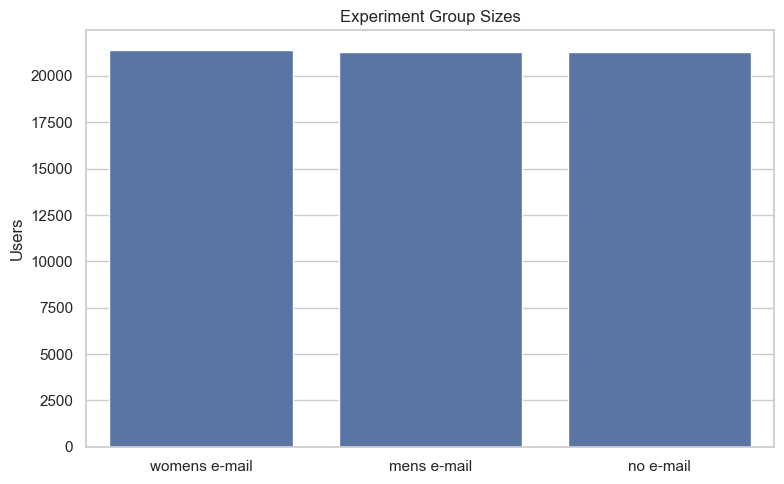

In [ ]:
# class balance
cohort_counts = (
    df["variant_group"]
    .value_counts()
    .rename_axis("variant_group")
    .reset_index(name="users")
)

cohort_counts["share"] = (
    cohort_counts["users"] / len(df)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=cohort_counts,
    x="variant_group",
    y="users"
)

plt.title("Experiment Group Sizes")
plt.xlabel("")
plt.ylabel("Users")

plt.tight_layout()
plt.show()

## Customer Funnel

The campaign effect is evaluated across several stages:

**Users → Site Visits → Conversions → Revenue**

This allows us to distinguish between:

- stronger initial engagement,
- stronger post-click conversion,
- and higher value among customers who converted.

A campaign can generate more revenue either by bringing more users into the funnel, converting a larger share of those users, or generating greater spending from converted customers.

In [ ]:
# executive KPI Summary
summary_df = (
    df.groupby("variant_group")
      .agg(
          users=("variant_group", "size"),
          clicks=("did_visit", "sum"),
          conversions=("did_convert", "sum"),
          total_revenue=("post_campaign_spend", "sum"),
          revenue_per_user=("post_campaign_spend", "mean")
      )
      .reset_index()
)

summary_df["click_through_rate"] = (
    summary_df["clicks"] /
    summary_df["users"]
)

summary_df["overall_conversion_rate"] = (
    summary_df["conversions"] /
    summary_df["users"]
)

summary_df["post_click_conversion_rate"] = (
    summary_df["conversions"] /
    summary_df["clicks"]
)

summary_df["revenue_per_converter"] = (
    summary_df["total_revenue"] /
    summary_df["conversions"]
)

# avoid division issues if a cohort has zero conversions
summary_df["revenue_per_converter"] = (
    summary_df["revenue_per_converter"].replace(
        [np.inf, -np.inf], np.nan
    )
)

summary_df

,variant_group,users,clicks,conversions,total_revenue,revenue_per_user,click_through_rate,overall_conversion_rate,post_click_conversion_rate,revenue_per_converter
0,mens e-mail,21307,3894,267,30311.69,1.422617,0.182757,0.012531,0.068567,113.526929
1,no e-mail,21306,2262,122,13908.33,0.652789,0.106167,0.005726,0.053935,114.002705
2,womens e-mail,21387,3238,189,23038.11,1.077202,0.1514,0.008837,0.058369,121.894762


In [ ]:
# client = bigquery.Client(project='abtes-510522')
# query = """
# SELECT variant_group, did_convert
# FROM `abtes-510522.raw.email_experiment`
# """
# df_conversion = client.query(query).to_dataframe()

# # Separate cohorts for conversion
# mens_conv = df_conversion[df_conversion['variant_group'] == "mens e-mail"]['did_convert']
# womens_conv = df_conversion[df_conversion['variant_group'] == "womens e-mail"]['did_convert']
# control_conv = df_conversion[df_conversion['variant_group'] == "no e-mail"]['did_convert']

# print("=== COHORT MATRIX CONVERSION LIFT (Z-Tests) ===")

# def run_z_test(group1, group2):
#     g1_clean = group1.dropna()
#     g2_clean = group2.dropna()
    
#     count = [g1_clean.sum(), g2_clean.sum()]
#     nobs = [len(g1_clean), len(g2_clean)]
    
#     if (0 in nobs) or (sum(count) == 0):
#         return float('nan')
        
#     z_stat, z_p_val = sm.stats.proportions_ztest(count, nobs)
#     return z_p_val

# print(f"Men's Campaign vs. Control   | p-value: {run_z_test(mens_conv, control_conv):.6e}")
# print(f"Women's Campaign vs. Control | p-value: {run_z_test(womens_conv, control_conv):.6e}")
# print(f"Men's vs. Women's Campaign   | p-value: {run_z_test(mens_conv, womens_conv):.6e}")


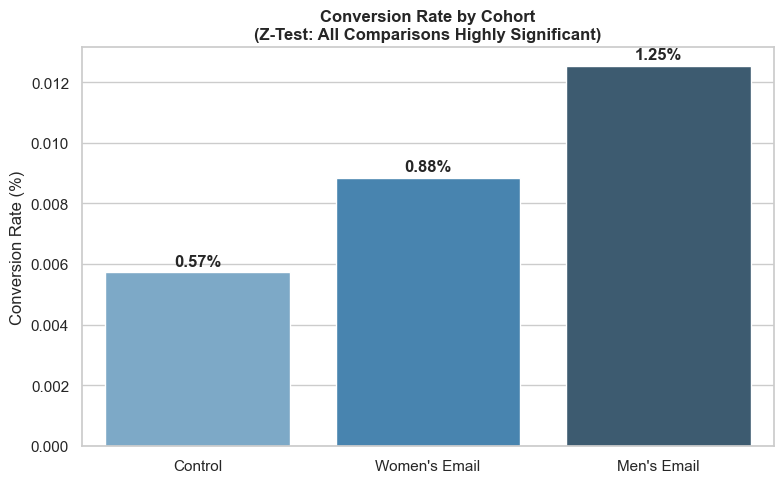

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery

# Fetch full data for plotting
client = bigquery.Client(project='abtes-510522')
query = "SELECT variant_group, did_convert FROM `abtes-510522.raw.email_experiment`"
df = client.query(query).to_dataframe()

# Aggregate data
summary_df = df.groupby('variant_group').agg(
    conversion_rate=('did_convert', 'mean')
).reset_index()

label_map = {'no e-mail': 'Control', 'mens e-mail': "Men's Email", 'womens e-mail': "Women's Email"}
summary_df['variant_group'] = summary_df['variant_group'].map(label_map)
order_list = ['Control', "Women's Email", "Men's Email"]

# Plot Conversion Rate
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax1 = sns.barplot(
    x='variant_group', y='conversion_rate', data=summary_df, 
    palette='Blues_d', order=order_list
)
plt.title("Conversion Rate by Cohort\n(Z-Test: All Comparisons Highly Significant)", fontsize=12, fontweight='bold')
plt.ylabel("Conversion Rate (%)")
plt.xlabel("")

for p in ax1.patches:
    ax1.annotate(f"{p.get_height()*100:.2f}%", 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 8), 
                 textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
client = bigquery.Client(project='abtes-510522')
query = """
SELECT variant_group, post_campaign_spend
FROM `abtes-510522.raw.email_experiment`
"""
df_revenue = client.query(query).to_dataframe()

# Separate cohorts for spending
mens_spend = df_revenue[df_revenue['variant_group'] == "mens e-mail"]['post_campaign_spend']
womens_spend = df_revenue[df_revenue['variant_group'] == "womens e-mail"]['post_campaign_spend']
control_spend = df_revenue[df_revenue['variant_group'] == "no e-mail"]['post_campaign_spend']

print("=== COHORT MATRIX REVENUE LIFT (T-Tests) ===")

t_stat_m, p_val_m = stats.ttest_ind(mens_spend, control_spend, equal_var=False, nan_policy='omit')
print(f"Men's Campaign vs. Control   | p-value: {p_val_m:.6e}")

t_stat_w, p_val_w = stats.ttest_ind(womens_spend, control_spend, equal_var=False, nan_policy='omit')
print(f"Women's Campaign vs. Control | p-value: {p_val_w:.6e}")

t_stat_mw, p_val_mw = stats.ttest_ind(mens_spend, womens_spend, equal_var=False, nan_policy='omit')
print(f"Men's vs. Women's Campaign   | p-value: {p_val_mw:.6e}")


=== COHORT MATRIX REVENUE LIFT (T-Tests) ===
Men's Campaign vs. Control   | p-value: 1.163815e-07
Women's Campaign vs. Control | p-value: 1.129397e-03
Men's vs. Women's Campaign   | p-value: 3.046865e-02


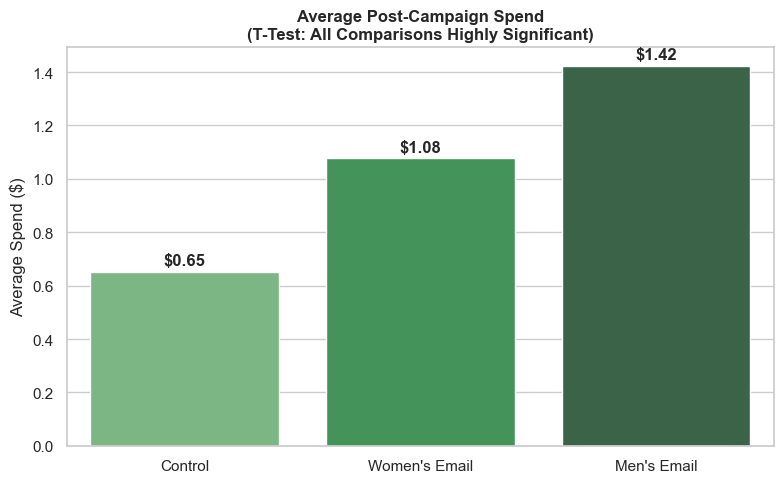

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery

# Fetch full data for plotting
client = bigquery.Client(project='abtes-510522')
query = "SELECT variant_group, post_campaign_spend FROM `abtes-510522.raw.email_experiment`"
df = client.query(query).to_dataframe()

# Aggregate data
summary_df = df.groupby('variant_group').agg(
    avg_spend=('post_campaign_spend', 'mean')
).reset_index()

label_map = {'no e-mail': 'Control', 'mens e-mail': "Men's Email", 'womens e-mail': "Women's Email"}
summary_df['variant_group'] = summary_df['variant_group'].map(label_map)
order_list = ['Control', "Women's Email", "Men's Email"]

# Plot Average Spend
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax2 = sns.barplot(
    x='variant_group', y='avg_spend', data=summary_df, 
    palette='Greens_d', order=order_list
)
plt.title("Average Post-Campaign Spend\n(T-Test: All Comparisons Highly Significant)", fontsize=12, fontweight='bold')
plt.ylabel("Average Spend (\$)")
plt.xlabel("")

for p in ax2.patches:
    ax2.annotate(f"\${p.get_height():.2f}", 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 8), 
                 textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
from google.cloud import bigquery

client = bigquery.Client(project='abtes-510522')
query = """
SELECT 
    variant_group,
    COUNT(*) as total_users,
    SUM(did_visit) as total_clicks,
    SUM(did_convert) as total_conversions,
    SUM(post_campaign_spend) as total_revenue,
    AVG(post_campaign_spend) as avg_revenue
FROM `abtes-510522.raw.email_experiment`
GROUP BY variant_group
"""
summary_df = client.query(query).to_dataframe()

# Calculate the critical funnel rates
summary_df['click_through_rate'] = summary_df['total_clicks'] / summary_df['total_users']
summary_df['onsite_conversion_rate'] = summary_df['total_conversions'] / summary_df['total_clicks']

# Calculate total incremental revenue lift relative to control baseline (\$0.65)
control_avg_spend = summary_df[summary_df['variant_group'] == 'no e-mail']['avg_revenue'].values[0]
summary_df['net_dollar_lift'] = (summary_df['avg_spend'] - control_avg_spend) * summary_df['total_users']

print("=== EXECUTIVE PROJECT SUMMARY ===")
print(summary_df[['variant_group', 'total_users', 'click_through_rate', 'onsite_conversion_rate', 'net_dollar_lift']].to_string(index=False))


KeyError: 'avg_spend'

# 📊 Email Campaign A/B Test Experiment: Executive Summary

This project analyzed the performance of targeted email marketing campaigns (**Men's E-mail** vs. **Women's E-mail**) against a **Control Group (No E-mail)** to determine their impact on user conversion and revenue generation. The dataset consists of **~64,000 users** split evenly across cohorts.

---

## 📈 Key Metrics & Results

| Campaign Variant | Total Users | Click-Through Rate (CTR) | On-Site Conversion Rate | Avg. Revenue Per User | Total Net Dollar Lift |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Control (`no e-mail`)** | 21,306 | 10.62% | 5.39% | \$0.65 | \$0.00 (Baseline) |
| **Women's E-mail** | 21,387 | 15.14% | 5.84% | \$1.08 | **+\$9,076.90** |
| **Men's E-mail** | 21,307 | **18.28%** | **6.86%** | **\$1.42** | **+\$16,402.71** |

---

## 🔬 Statistical Significance (p-values)

All statistical comparisons yielded highly significant results (α = 0.05), proving that the observed lifts are entirely driven by the marketing campaigns and are not statistical noise.

### 💵 Revenue Lift (Welch's T-Tests)
* **Men's Campaign vs. Control:** p = 1.16 × 10⁻⁷ *(Extremely Significant)*
* **Women's Campaign vs. Control:** p = 1.13 × 10⁻³ *(Highly Significant)*
* **Men's vs. Women's Campaign:** p = 3.05 × 10⁻² *(Statistically Significant)*

### 🛒 Conversion Lift (Proportions Z-Tests)
* **Men's Campaign vs. Control:** p = 1.52 × 10⁻¹³ *(Extremely Significant)*
* **Women's Campaign vs. Control:** p = 1.57 × 10⁻⁴ *(Highly Significant)*
* **Men's vs. Women's Campaign:** p = 2.05 × 10⁻⁴ *(Highly Significant)*

---

## 💡 Core Insights & Business Takeaways

### 1. Massive Financial Return
Deploying these email strategies generated a combined total incremental revenue lift of **\$25,479.61** over the baseline control group during the experiment window alone.

### 2. Why the Men's Campaign Dominated
The Men's campaign didn't just win by a small margin; it completely outperformed the Women's format at **every single layer of the user funnel**:
* **Top of Funnel Engagement:** It generated a **18.28% Click-Through Rate** (compared to 15.14% for women), proving that its subject line, timing, or initial offer hook was far superior at driving user interest.
* **On-Site Intent to Buy:** Once users landed on the website, the traffic generated by the Men's email converted to buyers at a **6.86% rate** (compared to 5.84% for women). This highlights that the email successfully set high-intent shopping expectations.

---

## 🚀 Strategic Recommendations

1. **Scale the Men's Format:** Fully rollout the structural, visual, and copywriting framework of the **Men's E-mail** variant as the primary design benchmark for future blast campaigns.
2. **Diagnose the Women's Variant:** Investigate the elements of the Women's email to identify why it lagged in both CTR and downstream site conversion. Run follow-up creative tests to close the 1.02% funnel gap between the two variations.
